# Módulo 47: Medidas y KPIs — Solución
*Juliho Castillo*

Enunciado para estudiantes: [m47-medidas-y-kpis-guia.ipynb](m47-medidas-y-kpis-guia.ipynb) · Lección: [m47-medidas-y-kpis-leccion.ipynb](m47-medidas-y-kpis-leccion.ipynb)

## Contexto

La dirección comercial quiere comparar las ventas con el mes y el año anteriores, ver el acumulado del año y conocer el importe con impuestos y el precio con descuento. Hay que escribir esas medidas sobre el modelo de ventas en DuckDB, reunirlas en un solo lugar y validarlas en una tabla por país y mes. El enunciado original del curso se perdió; las instrucciones de la guía se reconstruyeron a partir de la solución.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "png"
pio.defaults.default_width = 900
pio.defaults.default_height = 450

sys.path.insert(0, str(Path("../practica-ventas").resolve()))
import ventas as practica

con = practica.conectar()

def ver(tabla, porcentajes=()):
    # Separador de miles con espacio, porcentajes y celdas vacías en blanco
    sin_formato = {"anio", "mes", "trimestre"}
    formatos = {}
    for columna in tabla.select_dtypes("number").columns:
        if columna in porcentajes:
            formatos[columna] = lambda v: "" if pd.isna(v) else f"{v:.2%}"
        elif columna not in sin_formato:
            valores = tabla[columna].dropna()
            decimales = 0 if (valores == valores.round()).all() else 2
            formatos[columna] = lambda v, d=decimales: "" if pd.isna(v) else f"{v:,.{d}f}".replace(",", " ")
    return tabla.style.format(formatos).hide(axis="index")

### Tarea 1. Un módulo de medidas

In [2]:
MEDIDAS = {}


def registrar(funcion):
    # Reúne las medidas en un solo diccionario, aunque se definan en celdas distintas
    MEDIDAS[funcion.__name__] = funcion
    return funcion


def agregar(con, expresion, **filtros):
    # Evalúa una expresión agregada sobre ventas_detalle en el contexto de filtro dado
    where, params = practica.filtro_sql(**filtros)
    return con.execute(f"SELECT {expresion} FROM ventas_detalle {where}", params).fetchone()[0]


def rango_mes(anio, mes):
    # Primer y último día de un mes, para fijar el filtro de fechas
    inicio = pd.Timestamp(year=anio, month=mes, day=1)
    return inicio.date(), (inicio + pd.offsets.MonthEnd(0)).date()

`agregar` es la única función que habla con DuckDB; las medidas solo deciden qué expresión agregar y con qué contexto. `rango_mes` traduce un mes en el par `desde`/`hasta` que entiende `practica.filtro_sql`.

### Tarea 2. Medidas básicas

In [3]:
@registrar
def ventas_total(con, **filtros):
    return agregar(con, "CAST(sum(importe) AS BIGINT)", **filtros)


@registrar
def ventas_promedio(con, **filtros):
    return agregar(con, "avg(importe)", **filtros)


assert ventas_total(con) == practica.VENTAS_TOTALES
canada_2020 = ventas_total(con, paises=["CANADA"], desde="2020-01-01", hasta="2020-12-31")
print(f"Ventas totales: {ventas_total(con):,} | venta promedio: {ventas_promedio(con):,.2f}".replace(",", " "))
print(f"Canadá en 2020: {canada_2020:,}".replace(",", " "))
print("Contexto vacío:", ventas_total(con, paises=[]), ventas_promedio(con, paises=[]))

Ventas totales: 41 940 958 825 | venta promedio: 27 979.29
Canadá en 2020: 856 197 372
Contexto vacío: None None


Sin filtros, las ventas suman 41 940 958 825 y la venta promedio es 27 979.29; con el contexto Canadá–2020, 856 197 372. Un contexto sin filas devuelve `None`, el equivalente del blanco.

### Tarea 3. Comparaciones con el mes y el año anteriores

In [4]:
@registrar
def ventas_mes_anterior(con, anio, mes, **filtros):
    # Reutiliza ventas_total y solo reemplaza el rango de fechas por el del mes anterior
    anterior = pd.Timestamp(year=anio, month=mes, day=1) - pd.DateOffset(months=1)
    desde, hasta = rango_mes(anterior.year, anterior.month)
    return ventas_total(con, **(filtros | {"desde": desde, "hasta": hasta}))


@registrar
def ventas_mismo_mes_anio_anterior(con, anio, mes, **filtros):
    desde, hasta = rango_mes(anio - 1, mes)
    return ventas_total(con, **(filtros | {"desde": desde, "hasta": hasta}))


ver(pd.DataFrame([
    {"anio": anio, "mes": mes,
     "ventas_mes_anterior": ventas_mes_anterior(con, anio, mes),
     "ventas_mismo_mes_anio_anterior": ventas_mismo_mes_anio_anterior(con, anio, mes)}
    for anio, mes in [(2019, 1), (2020, 1), (2021, 1)]
]))

anio,mes,ventas_mes_anterior,ventas_mismo_mes_anio_anterior
2019,1,,
2020,1,1 958 766 078,1 055 072 666
2021,1,438 915 318,726 241 507


En enero de 2019 las dos medidas devuelven `None`, porque diciembre de 2018 y enero de 2018 no tienen ventas. El mes anterior a enero de 2020 es diciembre de 2019 (1 958 766 078): el desplazamiento cruza el cambio de año.

### Tarea 4. Acumulado del año y diferencia mensual

In [5]:
@registrar
def ventas_ytd(con, anio, mes, **filtros):
    desde = pd.Timestamp(year=anio, month=1, day=1).date()
    _, hasta = rango_mes(anio, mes)
    return ventas_total(con, **(filtros | {"desde": desde, "hasta": hasta}))


@registrar
def dif_mensual(con, anio, mes, **filtros):
    desde, hasta = rango_mes(anio, mes)
    actual = ventas_total(con, **(filtros | {"desde": desde, "hasta": hasta}))
    anterior = ventas_mes_anterior(con, anio, mes, **filtros)
    return None if actual is None or anterior is None else actual - anterior


print(f"Acumulado a diciembre de 2019: {ventas_ytd(con, 2019, 12):,}".replace(",", " "))
print(f"Acumulado a marzo de 2020:     {ventas_ytd(con, 2020, 3):,}".replace(",", " "))
print("Diferencia mensual 2019-01:", dif_mensual(con, 2019, 1))
print(f"Diferencia mensual 2020-01: {dif_mensual(con, 2020, 1):,}".replace(",", " "))
print("Medidas registradas:", list(MEDIDAS))

Acumulado a diciembre de 2019: 14 028 184 223
Acumulado a marzo de 2020:     1 827 831 842
Diferencia mensual 2019-01: None
Diferencia mensual 2020-01: -1 232 524 571
Medidas registradas: ['ventas_total', 'ventas_promedio', 'ventas_mes_anterior', 'ventas_mismo_mes_anio_anterior', 'ventas_ytd', 'dif_mensual']


El acumulado a diciembre de 2019 coincide con las ventas de todo 2019 (14 028 184 223), y en marzo de 2020 vuelve a empezar desde enero (1 827 831 842). La diferencia de enero de 2020 es negativa: −1 232 524 571 frente a diciembre. Las seis medidas quedan registradas en `MEDIDAS`.

### Tarea 5. Columnas calculadas

In [6]:
con.execute("""
    CREATE OR REPLACE VIEW ventas_calculadas AS
    SELECT *,
           importe * 1.20 AS ventas_con_impuestos,
           precio * 0.90 AS precio_con_descuento
    FROM ventas_detalle
""")
ver(con.execute("""
    SELECT CAST(fecha AS VARCHAR) AS fecha, pais, cantidad, precio, precio_con_descuento, importe, ventas_con_impuestos
    FROM ventas_calculadas
    LIMIT 3
""").df())

fecha,pais,cantidad,precio,precio_con_descuento,importe,ventas_con_impuestos
2019-01-01,US,208,112,100.80,23 296,27 955.20
2019-01-01,US,115,284,255.60,32 660,39 192.00
2019-01-01,US,39,94,84.60,3 666,4 399.20


In [7]:
total, con_impuestos = con.execute(
    "SELECT sum(importe), sum(ventas_con_impuestos) FROM ventas_calculadas"
).fetchone()
print(f"Ventas: {total:,} | con impuestos: {con_impuestos:,} | cociente: {con_impuestos / total}".replace(",", " "))
assert con_impuestos == total * 12 / 10

Ventas: 41 940 958 825 | con impuestos: 50 329 150 590.00 | cociente: 1.20


Las dos columnas se calculan fila a fila en la vista. `1.20` es un decimal exacto en DuckDB, así que la suma con impuestos es exactamente 1.2 veces las ventas: 50 329 150 590. A diferencia de las medidas, estas columnas se pueden agrupar o filtrar (por ejemplo, ventas con precio rebajado por debajo de cierto umbral).

### Tarea 6. Tabla de validación

In [8]:
validacion = con.execute("""
    WITH rejilla AS (
        SELECT DISTINCT c.anio, c.mes, p.pais
        FROM calendario c CROSS JOIN paises p
    ),
    base AS (
        SELECT pais, anio, mes, sum(importe) AS ventas
        FROM ventas_detalle
        GROUP BY ALL
    ),
    medidas AS (
        SELECT r.pais, r.anio, r.mes,
               CAST(b.ventas AS DOUBLE) AS ventas,
               CAST(lag(b.ventas) OVER w AS DOUBLE) AS ventas_mes_anterior,
               CAST(lag(b.ventas, 12) OVER w AS DOUBLE) AS ventas_mismo_mes_anio_anterior,
               CAST(sum(b.ventas) OVER (PARTITION BY r.pais, r.anio ORDER BY r.mes) AS DOUBLE) AS ventas_ytd
        FROM rejilla r
        LEFT JOIN base b USING (pais, anio, mes)
        WINDOW w AS (PARTITION BY r.pais ORDER BY r.anio, r.mes)
    )
    SELECT *, ventas - ventas_mes_anterior AS dif_mensual
    FROM medidas
    ORDER BY pais, anio, mes
""").df()
print(validacion.shape)
ver(validacion.head(13))

(360, 8)


pais,anio,mes,ventas,ventas_mes_anterior,ventas_mismo_mes_anio_anterior,ventas_ytd,dif_mensual
BRAZIL,2019,1,138 288 758,,,138 288 758,
BRAZIL,2019,2,133 790 589,138 288 758,,272 079 347,-4 498 169
BRAZIL,2019,3,260 146 663,133 790 589,,532 226 010,126 356 074
BRAZIL,2019,4,67 402 316,260 146 663,,599 628 326,-192 744 347
BRAZIL,2019,5,64 344 967,67 402 316,,663 973 293,-3 057 349
BRAZIL,2019,6,252 901 212,64 344 967,,916 874 505,188 556 245
BRAZIL,2019,7,71 339 049,252 901 212,,988 213 554,-181 562 163
BRAZIL,2019,8,67 433 591,71 339 049,,1 055 647 145,-3 905 458
BRAZIL,2019,9,65 814 370,67 433 591,,1 121 461 515,-1 619 221
BRAZIL,2019,10,264 915 089,65 814 370,,1 386 376 604,199 100 719


Una sola consulta calcula las cinco medidas para los 10 países y los 36 meses: la rejilla `calendario × paises` garantiza que cada país tenga sus 36 meses, y `PARTITION BY r.pais` reinicia las ventanas en cada país. Ahora las comprobaciones:

In [9]:
# 1. El mes anterior es la fila de arriba dentro del mismo país
arriba = validacion.groupby("pais")["ventas"].shift(1)
assert validacion["ventas_mes_anterior"].equals(arriba)

# 2. El acumulado se reinicia en enero
enero = validacion["mes"] == 1
assert (validacion.loc[enero, "ventas_ytd"] == validacion.loc[enero, "ventas"]).all()

# 3. Algunas celdas coinciden con las medidas de las tareas 3 y 4
for pais, anio, mes in [("CANADA", 2020, 1), ("FRANCE", 2021, 7), ("PERU", 2019, 12)]:
    fila = validacion.query("pais == @pais and anio == @anio and mes == @mes").iloc[0]
    assert fila["ventas_mes_anterior"] == ventas_mes_anterior(con, anio, mes, paises=[pais])
    assert fila["ventas_ytd"] == ventas_ytd(con, anio, mes, paises=[pais])
    assert fila["dif_mensual"] == dif_mensual(con, anio, mes, paises=[pais])

# 4. Coincide con la referencia de ventas.py
referencia = practica.ventas_mensuales(con, por="pais")
pd.testing.assert_frame_equal(validacion, referencia[validacion.columns])
print("Las cuatro comprobaciones pasan.")

Las cuatro comprobaciones pasan.


In [10]:
import tempfile

with tempfile.TemporaryDirectory() as carpeta:
    destino = Path(carpeta) / "validacion-medidas.csv"
    validacion.to_csv(destino, index=False)
    print(destino.name, f"{destino.stat().st_size / 1e3:.0f} kB,", len(pd.read_csv(destino)), "filas")

ver(validacion.query("pais == 'CANADA' and anio == 2020 and mes <= 3"))

validacion-medidas.csv 25 kB, 360 filas


pais,anio,mes,ventas,ventas_mes_anterior,ventas_mismo_mes_anio_anterior,ventas_ytd,dif_mensual
CANADA,2020,1,139 128 587,344 863 815,178 138 807,139 128 587,-205 735 228
CANADA,2020,2,123 711 238,139 128 587,162 886 071,262 839 825,-15 417 349
CANADA,2020,3,81 924 125,123 711 238,323 471 793,344 763 950,-41 787 113


En la fila de enero de 2020 de Canadá, el mes anterior es diciembre de 2019 y el acumulado vuelve a empezar; en febrero, el mes anterior es la venta de enero. La tabla se guarda como CSV (aquí en una carpeta temporal, para no ensuciar el repositorio); en la app del módulo, un `st.download_button` hace lo mismo.

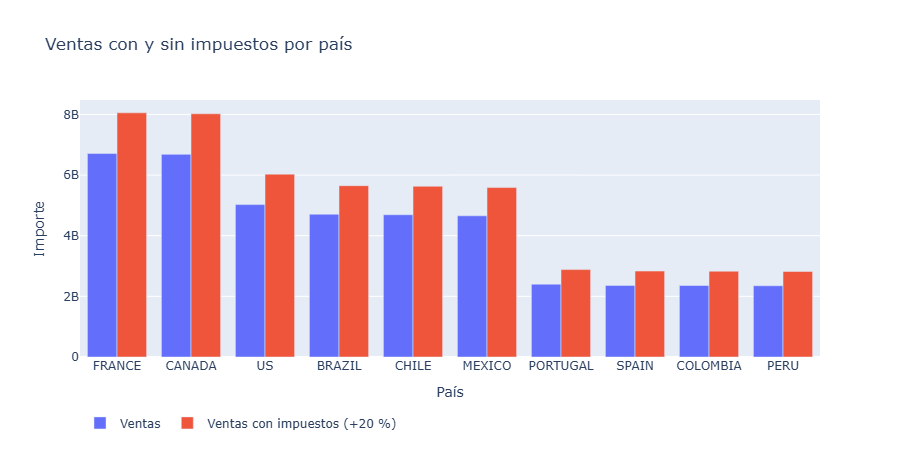

In [11]:
barras = con.execute("""
    SELECT pais,
           CAST(sum(importe) AS DOUBLE) AS ventas,
           CAST(sum(ventas_con_impuestos) AS DOUBLE) AS ventas_con_impuestos
    FROM ventas_calculadas
    GROUP BY pais
    ORDER BY ventas DESC
""").df()

fig = px.bar(
    barras.melt(id_vars="pais", var_name="medida", value_name="importe")
    .replace({"medida": {"ventas": "Ventas", "ventas_con_impuestos": "Ventas con impuestos (+20 %)"}}),
    x="pais", y="importe", color="medida", barmode="group",
    labels={"pais": "País", "importe": "Importe", "medida": ""},
    title="Ventas con y sin impuestos por país",
)
fig.update_layout(legend={"orientation": "h", "y": -0.2})
fig.show()

Francia y Canadá encabezan las ventas, y en cada país la barra con impuestos es un 20 % más alta, como corresponde a una columna calculada proporcional. El mapa de burbujas por país, con el tamaño según `ventas_promedio` y las ventas totales en la información emergente, está en la app [`m47-medidas-y-kpis-app.py`](m47-medidas-y-kpis-app.py), junto con la tabla de validación y este gráfico, filtrables por país y por meses.

**Revisión posterior (2026-10):** El ejercicio se resolvió originalmente en Power BI, con medidas DAX en una tabla de medidas y una página de validación exportada a PDF. Se rehízo en Python con DuckDB, pandas, Plotly y Streamlit para que la sección no dependa de software de pago ni de Windows; la versión original sigue en el historial de git.